# Week 8 - Task 1: LoRA Rank Visualization

This notebook does Task 1 from `DELIVERABLES.md`. The goal is to understand the basic idea behind LoRA. We check how well a matrix can be approximated with a small rank, and how many parameters that would use.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = Path.cwd().resolve()
if not (repo_root / "src").exists():
    repo_root = repo_root.parent

if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

from src.analysis import (
    DEFAULT_RANKS,
    lora_budget_table,
    lora_parameter_stats,
    make_diagonal_dominant_matrix,
    make_exact_rank_matrix,
    make_random_matrix,
    rank_approximation_errors,
)
from src.visualization import (
    plot_random_matrix_tradeoff,
    plot_structure_comparison,
)

SEED = 42
np.random.seed(SEED)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")

## Task 1.1 - SVD and rank approximation

We start with a random `512 x 512` matrix. Then we rebuild it with smaller ranks and measure the error. We also compare that to the LoRA parameter count `2 x D x r`.

In [2]:
dimension = 512
ranks = DEFAULT_RANKS

W = make_random_matrix(dimension=dimension, seed=SEED)
error_frame = rank_approximation_errors(W, ranks)
param_frame = lora_parameter_stats(dimension=dimension, ranks=ranks)
task_11_results = error_frame.merge(param_frame, on="rank")
task_11_view = task_11_results[["rank", "relative_error", "LoRA_params", "parameter_savings_pct"]]

task_11_view

,rank,relative_error,LoRA_params,parameter_savings_pct
0,1,0.996126,1024,99.609375
1,2,0.992283,2048,99.218750
2,4,0.984789,4096,98.437500
3,8,0.970178,8192,96.875000
4,16,0.942180,16384,93.750000
5,32,0.889066,32768,87.500000
6,64,0.790496,65536,75.000000
7,128,0.615262,131072,50.000000
8,512,0.000000,524288,-100.000000


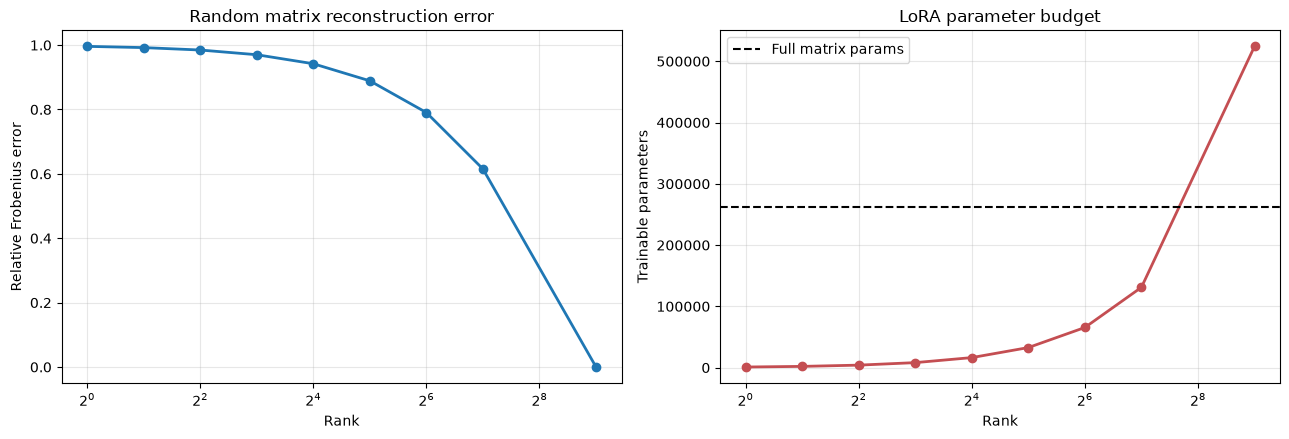

In [3]:
fig, _ = plot_random_matrix_tradeoff(task_11_results, dimension)

### Task 1.1 interpretation

The error goes down slowly for the random matrix. That is expected because a random matrix does not have a simple low-rank pattern.

This means a random update is hard to compress well with a very small rank. A real fine-tuning update can be different. If the task needs only a few important changes, the error can drop much faster, so a small LoRA rank can still work well.

## Task 1.2 - Elbow dependence on matrix structure

Here we compare three different kinds of matrices:

- a random dense matrix,
- an exactly rank-10 matrix, and
- a diagonal-dominant matrix with small noise.

The goal is to show that low-rank approximation works better for some matrix types than for others.

In [4]:
random_matrix = make_random_matrix(dimension=512, seed=SEED)
exact_rank_10_matrix = make_exact_rank_matrix(dimension=512, intrinsic_rank=10, seed=7)
diagonal_dominant_matrix = make_diagonal_dominant_matrix(dimension=512, seed=21)

comparison_curves = {
    "Random dense": rank_approximation_errors(random_matrix, ranks),
    "Exact rank-10": rank_approximation_errors(exact_rank_10_matrix, ranks),
    "Diagonal-dominant": rank_approximation_errors(diagonal_dominant_matrix, ranks),
}

exact_rank_focus = rank_approximation_errors(exact_rank_10_matrix, list(range(1, 17)))
exact_rank_focus_view = exact_rank_focus.query("rank in [8, 10, 16]")

exact_rank_focus_view

,rank,relative_error
7,8,0.345299
9,10,0.000000
15,16,0.000000


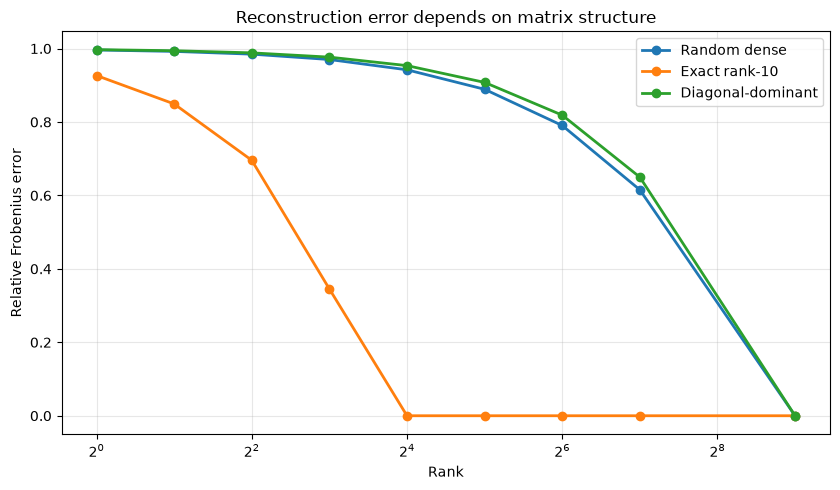

In [5]:
fig, _ = plot_structure_comparison(comparison_curves)

### Task 1.2 interpretation

The exact rank-10 matrix reaches almost zero error at rank 10. That happens because the matrix was built to need only 10 directions.

After rank 10, adding more rank does not help much because there is almost nothing left to recover. This is useful for LoRA too. If rank 16 is best and rank 32 does not help, the task may only need a small effective rank. If rank 32 starts to overfit, it may be learning noise instead of useful task information.

## Task 1.3 - Parameter budget table

For one square `D x D` layer, LoRA trains `D x r + r x D = 2Dr` parameters. The full layer has `D^2` parameters. The table below shows how small the LoRA part stays as the layer gets wider.

In [6]:
budget_table = lora_budget_table(
    dimensions=[512, 1024, 2048, 4096],
    ranks=[4, 8, 16, 32],
)

budget_table

,dimension,rank,A_params,B_params,LoRA_params,full_weight_params,lora_pct_of_full,parameter_savings_pct
0,512,4,2048,2048,4096,262144,1.562500,98.437500
1,512,8,4096,4096,8192,262144,3.125000,96.875000
2,512,16,8192,8192,16384,262144,6.250000,93.750000
3,512,32,16384,16384,32768,262144,12.500000,87.500000
4,1024,4,4096,4096,8192,1048576,0.781250,99.218750
5,1024,8,8192,8192,16384,1048576,1.562500,98.437500
6,1024,16,16384,16384,32768,1048576,3.125000,96.875000
7,1024,32,32768,32768,65536,1048576,6.250000,93.750000
8,2048,4,8192,8192,16384,4194304,0.390625,99.609375
9,2048,8,16384,16384,32768,4194304,0.781250,99.218750


In [7]:
budget_table.query("dimension == 4096")[[
    "rank",
    "A_params",
    "B_params",
    "LoRA_params",
    "full_weight_params",
    "lora_pct_of_full",
]]

,rank,A_params,B_params,LoRA_params,full_weight_params,lora_pct_of_full
12,4,16384,16384,32768,16777216,0.195312
13,8,32768,32768,65536,16777216,0.390625
14,16,65536,65536,131072,16777216,0.781250
15,32,131072,131072,262144,16777216,1.562500


### Task 1.3 interpretation

At rank 16, a `4096 x 4096` layer trains only `131,072` LoRA parameters instead of `16,777,216`. That is about `0.78%` of the full layer. As the model gets wider, the full matrix grows much faster than the LoRA part, so LoRA becomes even more useful for large models.